In [1]:
import sys, os, joblib, pandas as pd, numpy as np, matplotlib.pyplot as plt, shap
P = r"C:\Users\harsh\Downloads\churn-project (1)\churn-project"
sys.path.append(os.path.join(P, "src"))
from preprocess import load_data, split_data, build_preprocessor
from sklearn.pipeline import Pipeline

art = joblib.load(os.path.join(P, "models", "final_model.joblib"))
pipe, threshold = art["pipeline"], art["threshold"]
df = load_data(os.path.join(P, "data", "churn_clean.csv"))
X_train, X_test, y_train, y_test = split_data(df)
prep, model = pipe.named_steps["prep"], pipe.named_steps["model"]
Xt = prep.transform(X_test)
FIG = os.path.join(P, "reports", "figures")
print(art["model_name"], threshold, Xt.shape)

XGBoost 0.290098637342453 (2000, 16)


In [2]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


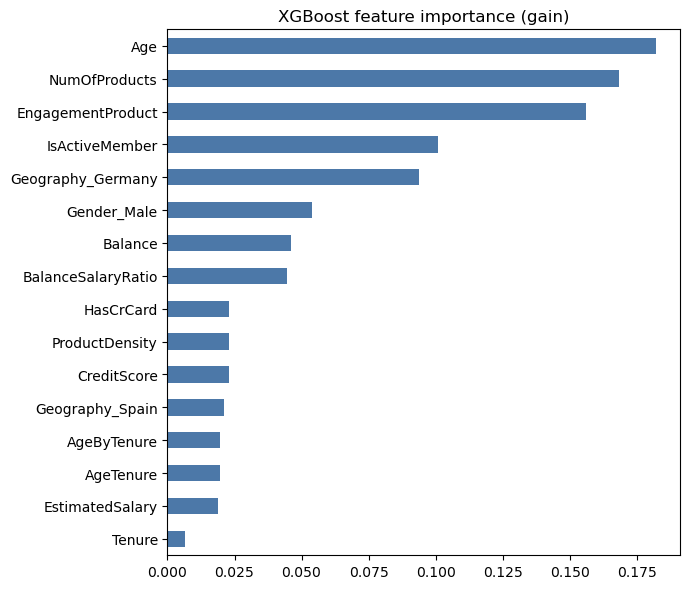

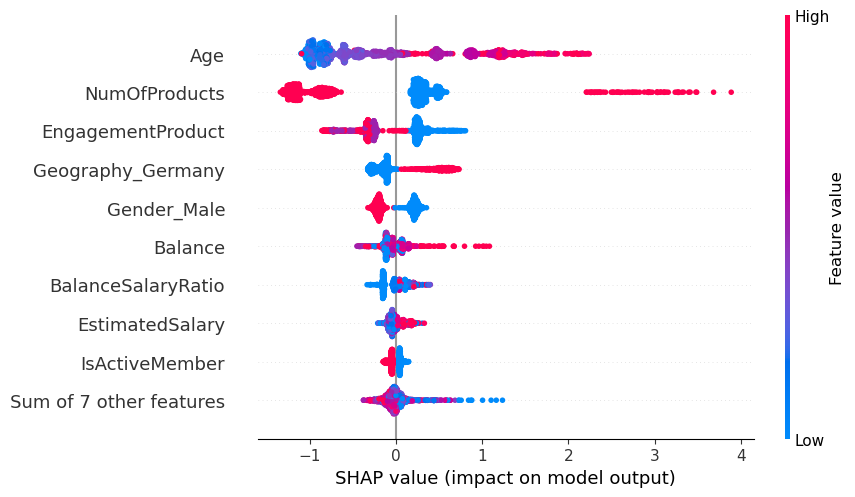

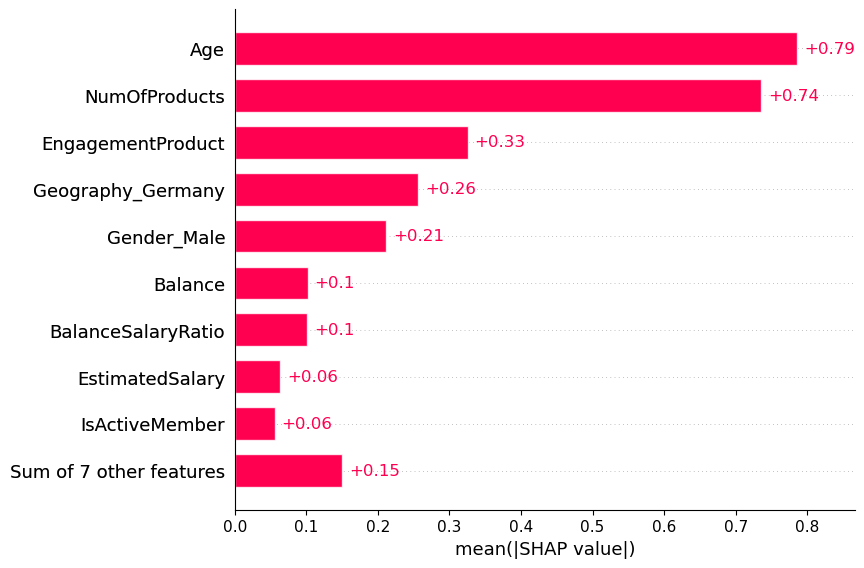

In [3]:
imp = pd.Series(model.feature_importances_, index=Xt.columns).sort_values()
imp.plot(kind="barh", figsize=(7, 6), color="#4C78A8", title="XGBoost feature importance (gain)")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "17_feature_importance.png"), dpi=150); plt.show()

explainer = shap.TreeExplainer(model)
sv = explainer(Xt)
shap.plots.beeswarm(sv, show=False)
plt.savefig(os.path.join(FIG, "18_shap_beeswarm.png"), dpi=150, bbox_inches="tight"); plt.show()
shap.plots.bar(sv, show=False)
plt.savefig(os.path.join(FIG, "19_shap_bar.png"), dpi=150, bbox_inches="tight"); plt.show()

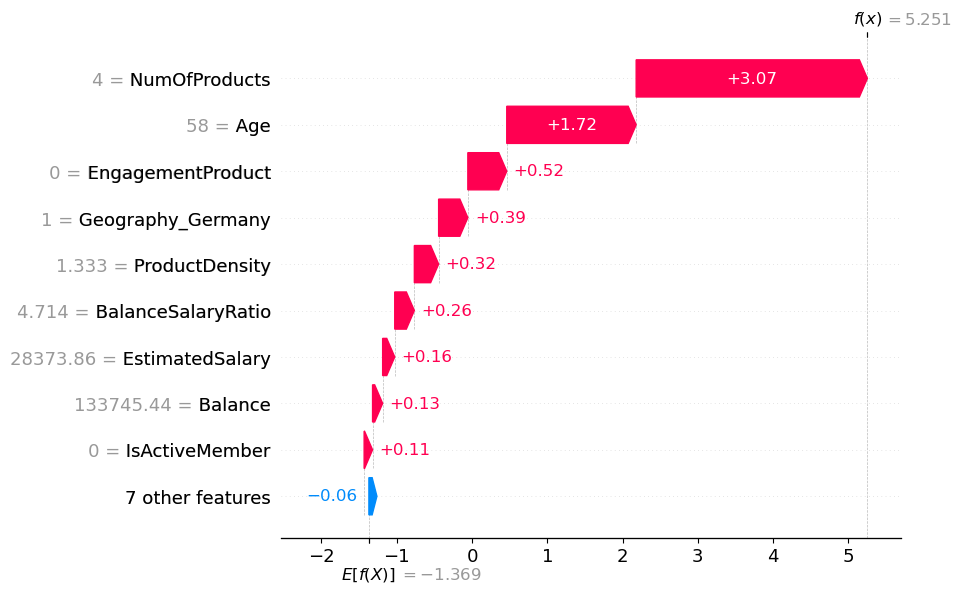

high_risk | risk 0.995 | actually left: 1
{'CreditScore': 738, 'Geography': 'Germany', 'Gender': 'Male', 'Age': 58, 'Tenure': 2, 'Balance': 133745.44, 'NumOfProducts': 4, 'HasCrCard': 1, 'IsActiveMember': 0, 'EstimatedSalary': 28373.86} 



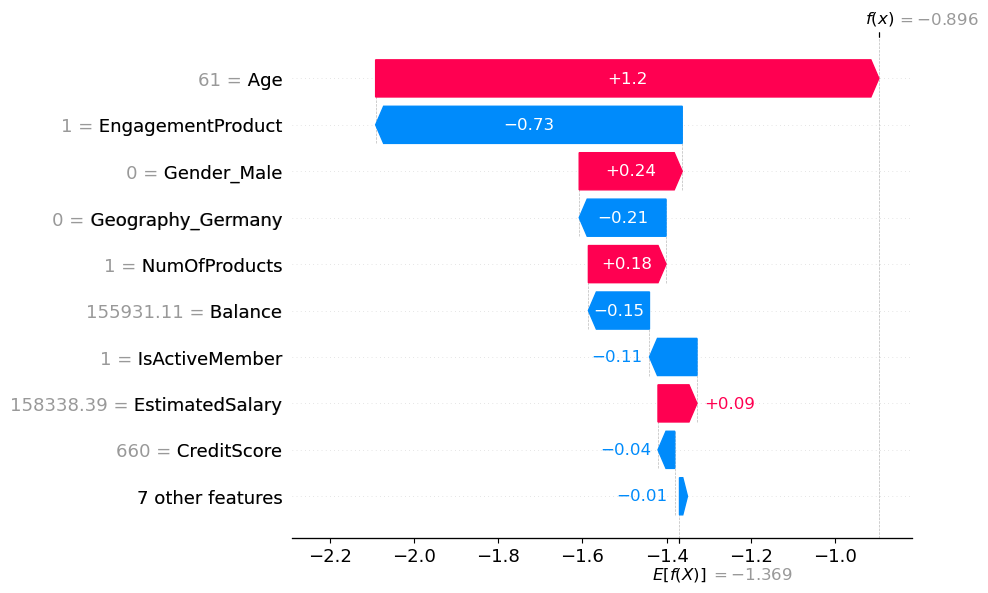

near_threshold | risk 0.29 | actually left: 0
{'CreditScore': 660, 'Geography': 'Spain', 'Gender': 'Female', 'Age': 61, 'Tenure': 5, 'Balance': 155931.11, 'NumOfProducts': 1, 'HasCrCard': 1, 'IsActiveMember': 1, 'EstimatedSalary': 158338.39} 



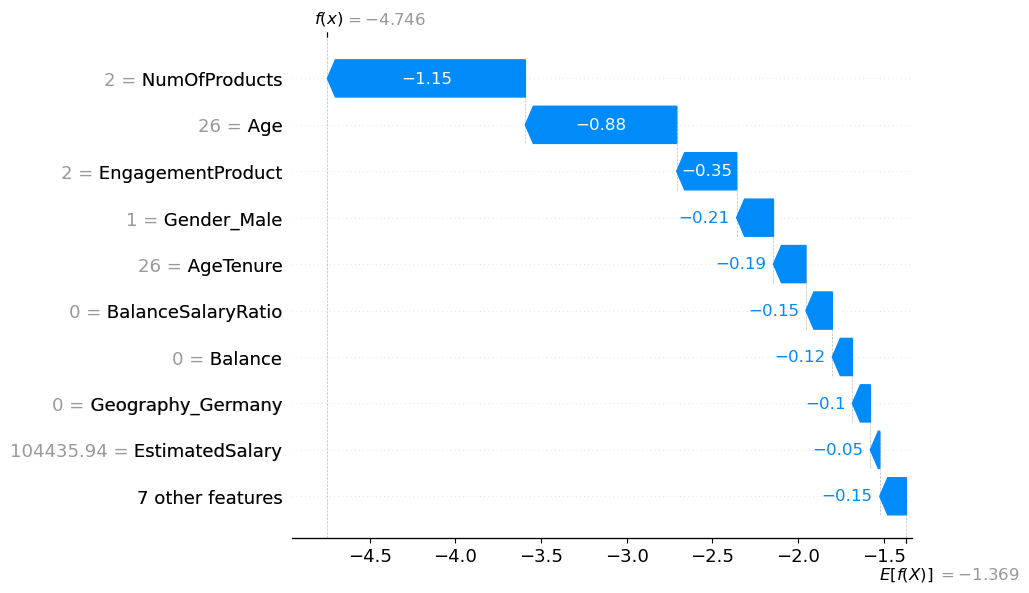

low_risk | risk 0.009 | actually left: 0
{'CreditScore': 688, 'Geography': 'France', 'Gender': 'Male', 'Age': 26, 'Tenure': 1, 'Balance': 0.0, 'NumOfProducts': 2, 'HasCrCard': 1, 'IsActiveMember': 1, 'EstimatedSalary': 104435.94} 



In [4]:
proba = pipe.predict_proba(X_test)[:, 1]
picks = {"high_risk": int(np.argmax(proba)),
         "near_threshold": int(np.argmin(np.abs(proba - threshold))),
         "low_risk": int(np.argmin(proba))}
for k, (name, i) in enumerate(picks.items()):
    shap.plots.waterfall(sv[i], show=False)
    plt.savefig(os.path.join(FIG, f"2{k}_shap_waterfall_{name}.png"), dpi=150, bbox_inches="tight")
    plt.show()
    print(name, "| risk", round(proba[i], 3), "| actually left:", int(y_test.iloc[i]))
    print(X_test.iloc[i].to_dict(), "\n")

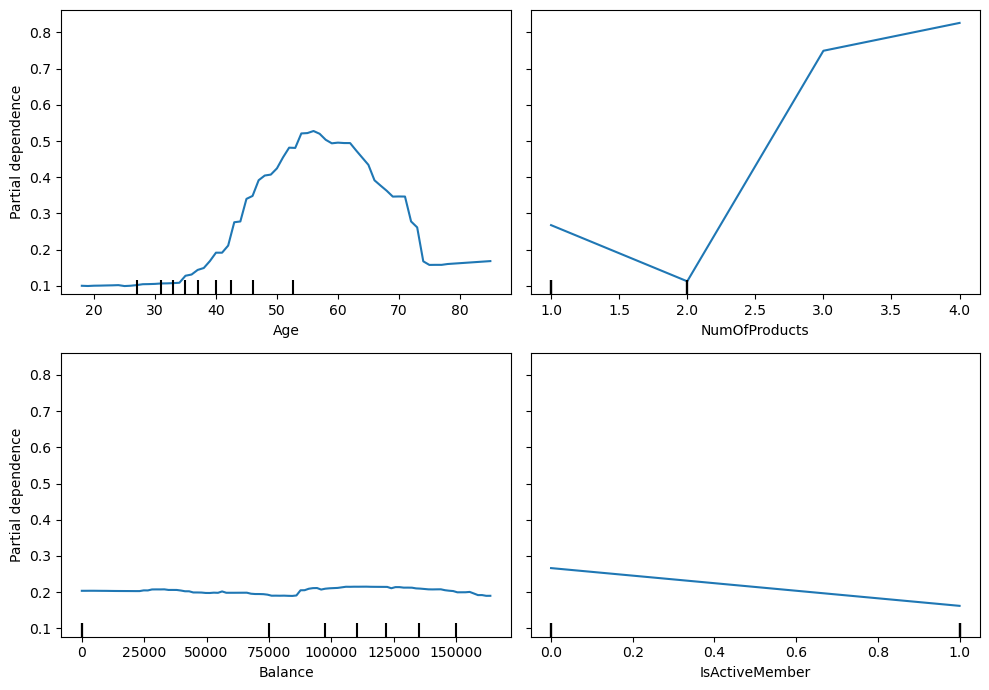

,SHAP importance,SHAP direction,LogReg coef,LogReg direction,SHAP rank,LogReg rank
Age,0.786,+,0.696,+,1,3
NumOfProducts,0.736,-,-0.124,-,2,8
EngagementProduct,0.325,-,0.272,+,3,5
Geography_Germany,0.256,+,0.816,+,4,2
Gender_Male,0.212,-,-0.524,-,5,4
Balance,0.102,+,0.160,+,6,7
BalanceSalaryRatio,0.101,+,0.160,+,7,6
EstimatedSalary,0.064,+,0.053,+,8,12
IsActiveMember,0.056,-,-1.494,-,9,1
CreditScore,0.048,-,-0.088,-,10,9


In [5]:
from sklearn.inspection import PartialDependenceDisplay
from sklearn.linear_model import LogisticRegression

Xf = X_test.astype({c: float for c in X_test.select_dtypes("int").columns})
fig, ax = plt.subplots(2, 2, figsize=(10, 7))
PartialDependenceDisplay.from_estimator(pipe, Xf, ["Age", "NumOfProducts", "Balance", "IsActiveMember"],
                                        response_method="predict_proba", ax=ax)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "23_partial_dependence.png"), dpi=150); plt.show()

lr = Pipeline([("prep", build_preprocessor(True)), ("model", LogisticRegression(max_iter=1000))]).fit(X_train, y_train)
coef = pd.Series(lr.named_steps["model"].coef_[0], index=lr.named_steps["prep"].transform(X_test).columns)
shap_mean = pd.Series(np.abs(sv.values).mean(axis=0), index=Xt.columns)
shap_dir = pd.Series([np.corrcoef(Xt[c], sv.values[:, j])[0, 1] for j, c in enumerate(Xt.columns)], index=Xt.columns)
cmp = pd.DataFrame({"SHAP importance": shap_mean, "SHAP direction": np.where(shap_dir > 0, "+", "-"),
                    "LogReg coef": coef, "LogReg direction": np.where(coef > 0, "+", "-")})
cmp["SHAP rank"] = cmp["SHAP importance"].rank(ascending=False).astype(int)
cmp["LogReg rank"] = cmp["LogReg coef"].abs().rank(ascending=False).astype(int)
cmp = cmp.sort_values("SHAP rank").round(3)
cmp.to_csv(os.path.join(P, "reports", "day6_logreg_vs_shap.csv"))
cmp

In [6]:
def ratio(a, b): return round(df[a]["Exited"].mean() / df[b]["Exited"].mean(), 1)
SHAP importance	SHAP direction	LogReg coef	LogReg direction	SHAP rank	LogReg rank
Age	0.786	+	0.696	+	1	3
NumOfProducts	0.736	-	-0.124	-	2	8
EngagementProduct	0.325	-	0.272	+	3	5
Geography_Germany	0.256	+	0.816	+	4	2
Gender_Male	0.212	-	-0.524	-	5	4
Balance	0.102	+	0.160	+	6	7
BalanceSalaryRatio	0.101	+	0.160	+	7	6
EstimatedSalary	0.064	+	0.053	+	8	12
IsActiveMember	0.056	-	-1.494	-	9	1
CreditScore	0.048	-	-0.088	-	10	9
AgeByTenure	0.043	+	0.076	+	11	10
AgeTenure	0.026	+	0.045	+	12	14
ProductDensity	0.020	+	-0.037	-	13	15
Geography_Spain	0.007	+	0.051	+	14	13
HasCrCard	0.005	-	-0.071	-	15	11
Tenure	0.001	+	-0.030	-	16	16

print("Inactive vs active members:", ratio(df.IsActiveMember == 0, df.IsActiveMember == 1), "x")
print("Germany vs France/Spain:", ratio(df.Geography == "Germany", df.Geography.isin(["France", "Spain"])), "x")
print("Women vs men:", ratio(df.Gender == "Female", df.Gender == "Male"), "x")
print("Age 45-60 vs under 40:", ratio(df.Age.between(45, 60), df.Age < 40), "x")
print("3-4 products vs 2 products:", ratio(df.NumOfProducts >= 3, df.NumOfProducts == 2), "x")

Inactive vs active members: 1.9 x
Germany vs France/Spain: 2.0 x
Women vs men: 1.5 x
Age 45-60 vs under 40: 5.0 x
3-4 products vs 2 products: 11.3 x
